# HA1 — Graded abstractness simulator (team working draft)

This notebook runs on the instructor-accepted **20 Chinese + 20 English** working HA0 dataset in `data/final/spatial_relations_zh20_en20_v3_working.csv`. Xia Yuqi manually confirmed the selected lexical senses. The seven-feature score audit is AI-assisted and flags nine value-level questions for team discussion; no new independent human rating is claimed. The 25 numeric S paths are reported from prior work and have not been independently revalidated. Fifteen S values remain NA.

Run all cells from a directory inside the repository. The output table and figures are saved in `submissions/team/HA1/`. The HA0 table is in `submissions/team/HA0/`, and score-level reasons are in `data/reviews/feature_score_audit_v3.csv`.

In [1]:
from pathlib import Path
import platform, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

current = Path.cwd().resolve()
repo = next((p for p in (current, *current.parents)
             if (p / 'data/final/spatial_relations_zh20_en20_v3_working.csv').is_file()), None)
if repo is None:
    raise FileNotFoundError("Open this notebook inside the repository or run it from its root")
work = repo / "submissions/team/HA1"
sys.path.insert(0, str(work))
from ha1_model import (
    FEATURES, abstractness, add_weight_settings, compute_c_raw, compute_s_raw,
    crossing_pairs, load_inventory, prepare_scores, scatter_plot, weight_sensitivity_plot
)
print("Python", platform.python_version(), "| NumPy", np.__version__,
      "| pandas", pd.__version__)


Python 3.13.14 | NumPy 2.5.3 | pandas 3.0.5


## 1. Separate C and S

`C_raw` is the **mean** of the seven 0–2 scores. `S_raw` counts edges in a reported root-to-sense path. A missing path stays **NA**. Both measures receive dataset-level min–max scaling; adding or changing senses can move existing normalized coordinates.

In [2]:
inventory = load_inventory(repo / "data/final/spatial_relations_zh20_en20_v3_working.csv")
scores = add_weight_settings(prepare_scores(inventory, c_aggregation="mean"))
display(scores[["concept_id","language","term","C_raw","C_norm","S_raw","S_norm",
                "quadrant","A_0.2","A_0.5","A_0.8"]].head(10))
print("C raw range:", scores.C_raw.min(), "to", scores.C_raw.max())
print("S raw range:", scores.S_raw.min(), "to", scores.S_raw.max())
print("S missing:", scores.S_raw.isna().sum(), "of", len(scores))

,concept_id,language,term,C_raw,C_norm,S_raw,S_norm,quadrant,A_0.2,A_0.5,A_0.8
0,ZH01,ZH,位置,0.571429,0.6,3.0,0.0,high_C_low_S,0.88,0.7,0.52
1,ZH02,ZH,内部,0.571429,0.6,5.0,0.4,high_C_low_S,0.56,0.5,0.44
2,ZH03,ZH,外部,0.571429,0.6,NaN,NaN,NA_S,NaN,NaN,NaN
3,ZH04,ZH,边界,0.428571,0.4,5.0,0.4,low_C_low_S,0.60,0.6,0.60
4,ZH05,ZH,中心,0.428571,0.4,5.0,0.4,low_C_low_S,0.60,0.6,0.60
5,ZH06,ZH,前面,0.428571,0.4,6.0,0.6,low_C_high_S,0.44,0.5,0.56
6,ZH07,ZH,左侧,0.571429,0.6,6.0,0.6,high_C_high_S,0.40,0.4,0.40
7,ZH08,ZH,坡度,0.571429,0.6,5.0,0.4,high_C_low_S,0.56,0.5,0.44
8,ZH09,ZH,上方,0.428571,0.4,NaN,NaN,NA_S,NaN,NaN,NaN
9,ZH10,ZH,下方,0.428571,0.4,NaN,NaN,NA_S,NaN,NaN,NaN


C raw range: 0.14285714285714285 to 0.8571428571428571
S raw range: 3.0 to 8.0
S missing: 15 of 40


In [3]:
# Calculation checks: path depth, seven scores, normalization, and NA propagation.
assert np.allclose(scores.C_raw, scores[list(FEATURES)].mean(axis=1))
assert np.allclose(scores.C_norm.min(), 0) and np.allclose(scores.C_norm.max(), 1)
assert np.allclose(scores.S_norm.min(), 0) and np.allclose(scores.S_norm.max(), 1)
assert scores.S_raw.isna().sum() == 15
assert scores.loc[scores.S_raw.isna(), ["S_norm","A_0.2","A_0.5","A_0.8"]].isna().all().all()
print("All calculation checks passed.")

All calculation checks passed.


## 2. C×S plane

Dashed boundaries are at 0.5 on the normalized axes. The graph shows 25 senses with reported S paths; 15 S=NA rows remain in the CSV and are excluded from the plot. The taxonomy sources still need independent sense-by-sense verification.

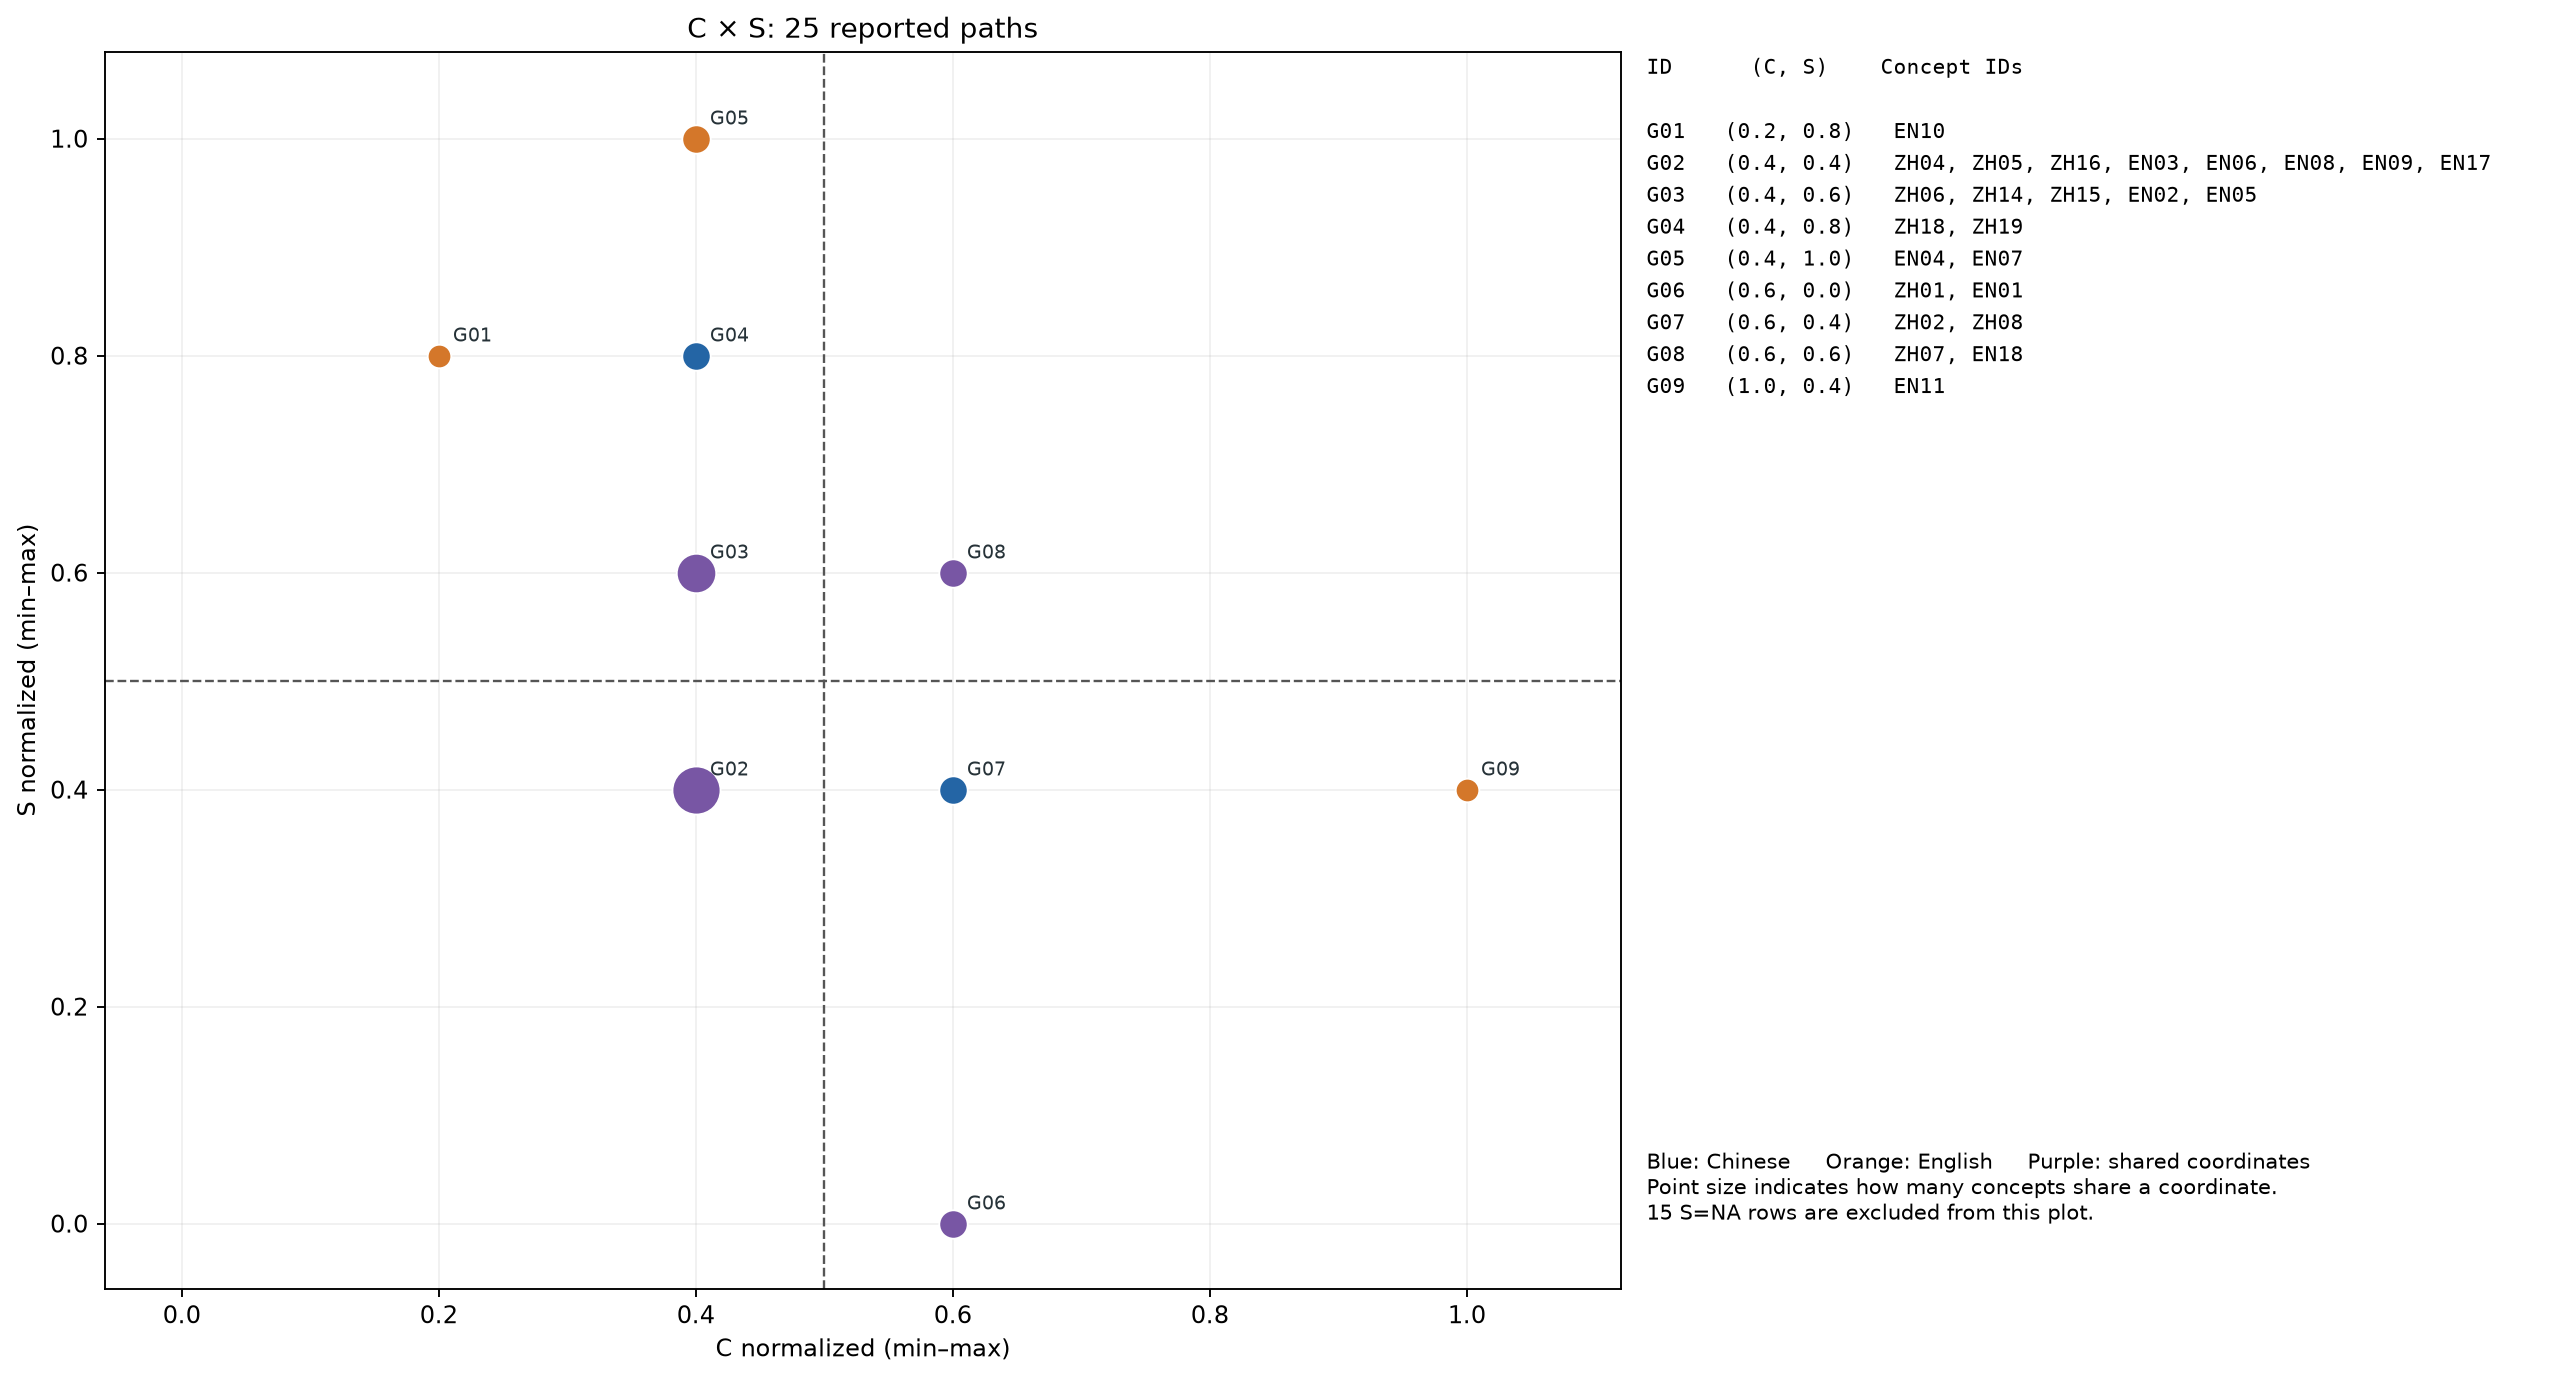

quadrant,low_C_low_S,low_C_high_S,high_C_low_S,high_C_high_S,NA_S
language,,,,,
EN,5,5,2,1,7
ZH,3,5,3,1,8


In [4]:
scatter_file = work / "figures/cs_scatter_ha1.png"
scatter_plot(scores, scatter_file)
display(Image(filename=str(scatter_file)))
display(pd.crosstab(scores.language, scores.quadrant).reindex(
    columns=["low_C_low_S","low_C_high_S","high_C_low_S","high_C_high_S","NA_S"],
    fill_value=0))

## 3. Adjustable composite

The function below accepts any `w` from 0 to 1. It always reports the two axes beside `A(w)=w(1-C_norm)+(1-w)(1-S_norm)`. The required settings 0.2, 0.5, and 0.8 are saved in the output table. `w=1` and `w=0` are C-only and S-only comparison baselines, not independent validity tests.

In [5]:
def show_weight(w=0.5, top_n=10):
    table = scores[["concept_id","language","term","C_norm","S_norm"]].copy()
    table["A"] = abstractness(scores, w)
    return table.dropna(subset=["A"]).sort_values("A", ascending=False).head(top_n)

display(show_weight(0.5))
# Optional live slider in Jupyter:
# from ipywidgets import interact, FloatSlider
# interact(show_weight, w=FloatSlider(value=0.5, min=0, max=1, step=0.1))

,concept_id,language,term,C_norm,S_norm,A
0,ZH01,ZH,位置,0.6,0.0,0.7
20,EN01,EN,location,0.6,0.0,0.7
3,ZH04,ZH,边界,0.4,0.4,0.6
28,EN09,EN,angle,0.4,0.4,0.6
4,ZH05,ZH,中心,0.4,0.4,0.6
25,EN06,EN,gap,0.4,0.4,0.6
22,EN03,EN,center,0.4,0.4,0.6
15,ZH16,ZH,路径,0.4,0.4,0.6
36,EN17,EN,path,0.4,0.4,0.6
27,EN08,EN,alignment,0.4,0.4,0.6


## 4. Sensitivity and error analysis

The line plot varies w from 0 to 1 in steps of 0.1. A sense is weight-sensitive when A changes by more than 0.1 between w=0.2 and 0.8. Pair crossings count rank reversals. We also compare mean, sum, maximum, and active-channel C aggregation rules. Nine disputed feature cells are documented separately; their retained values are not team-adjudicated.

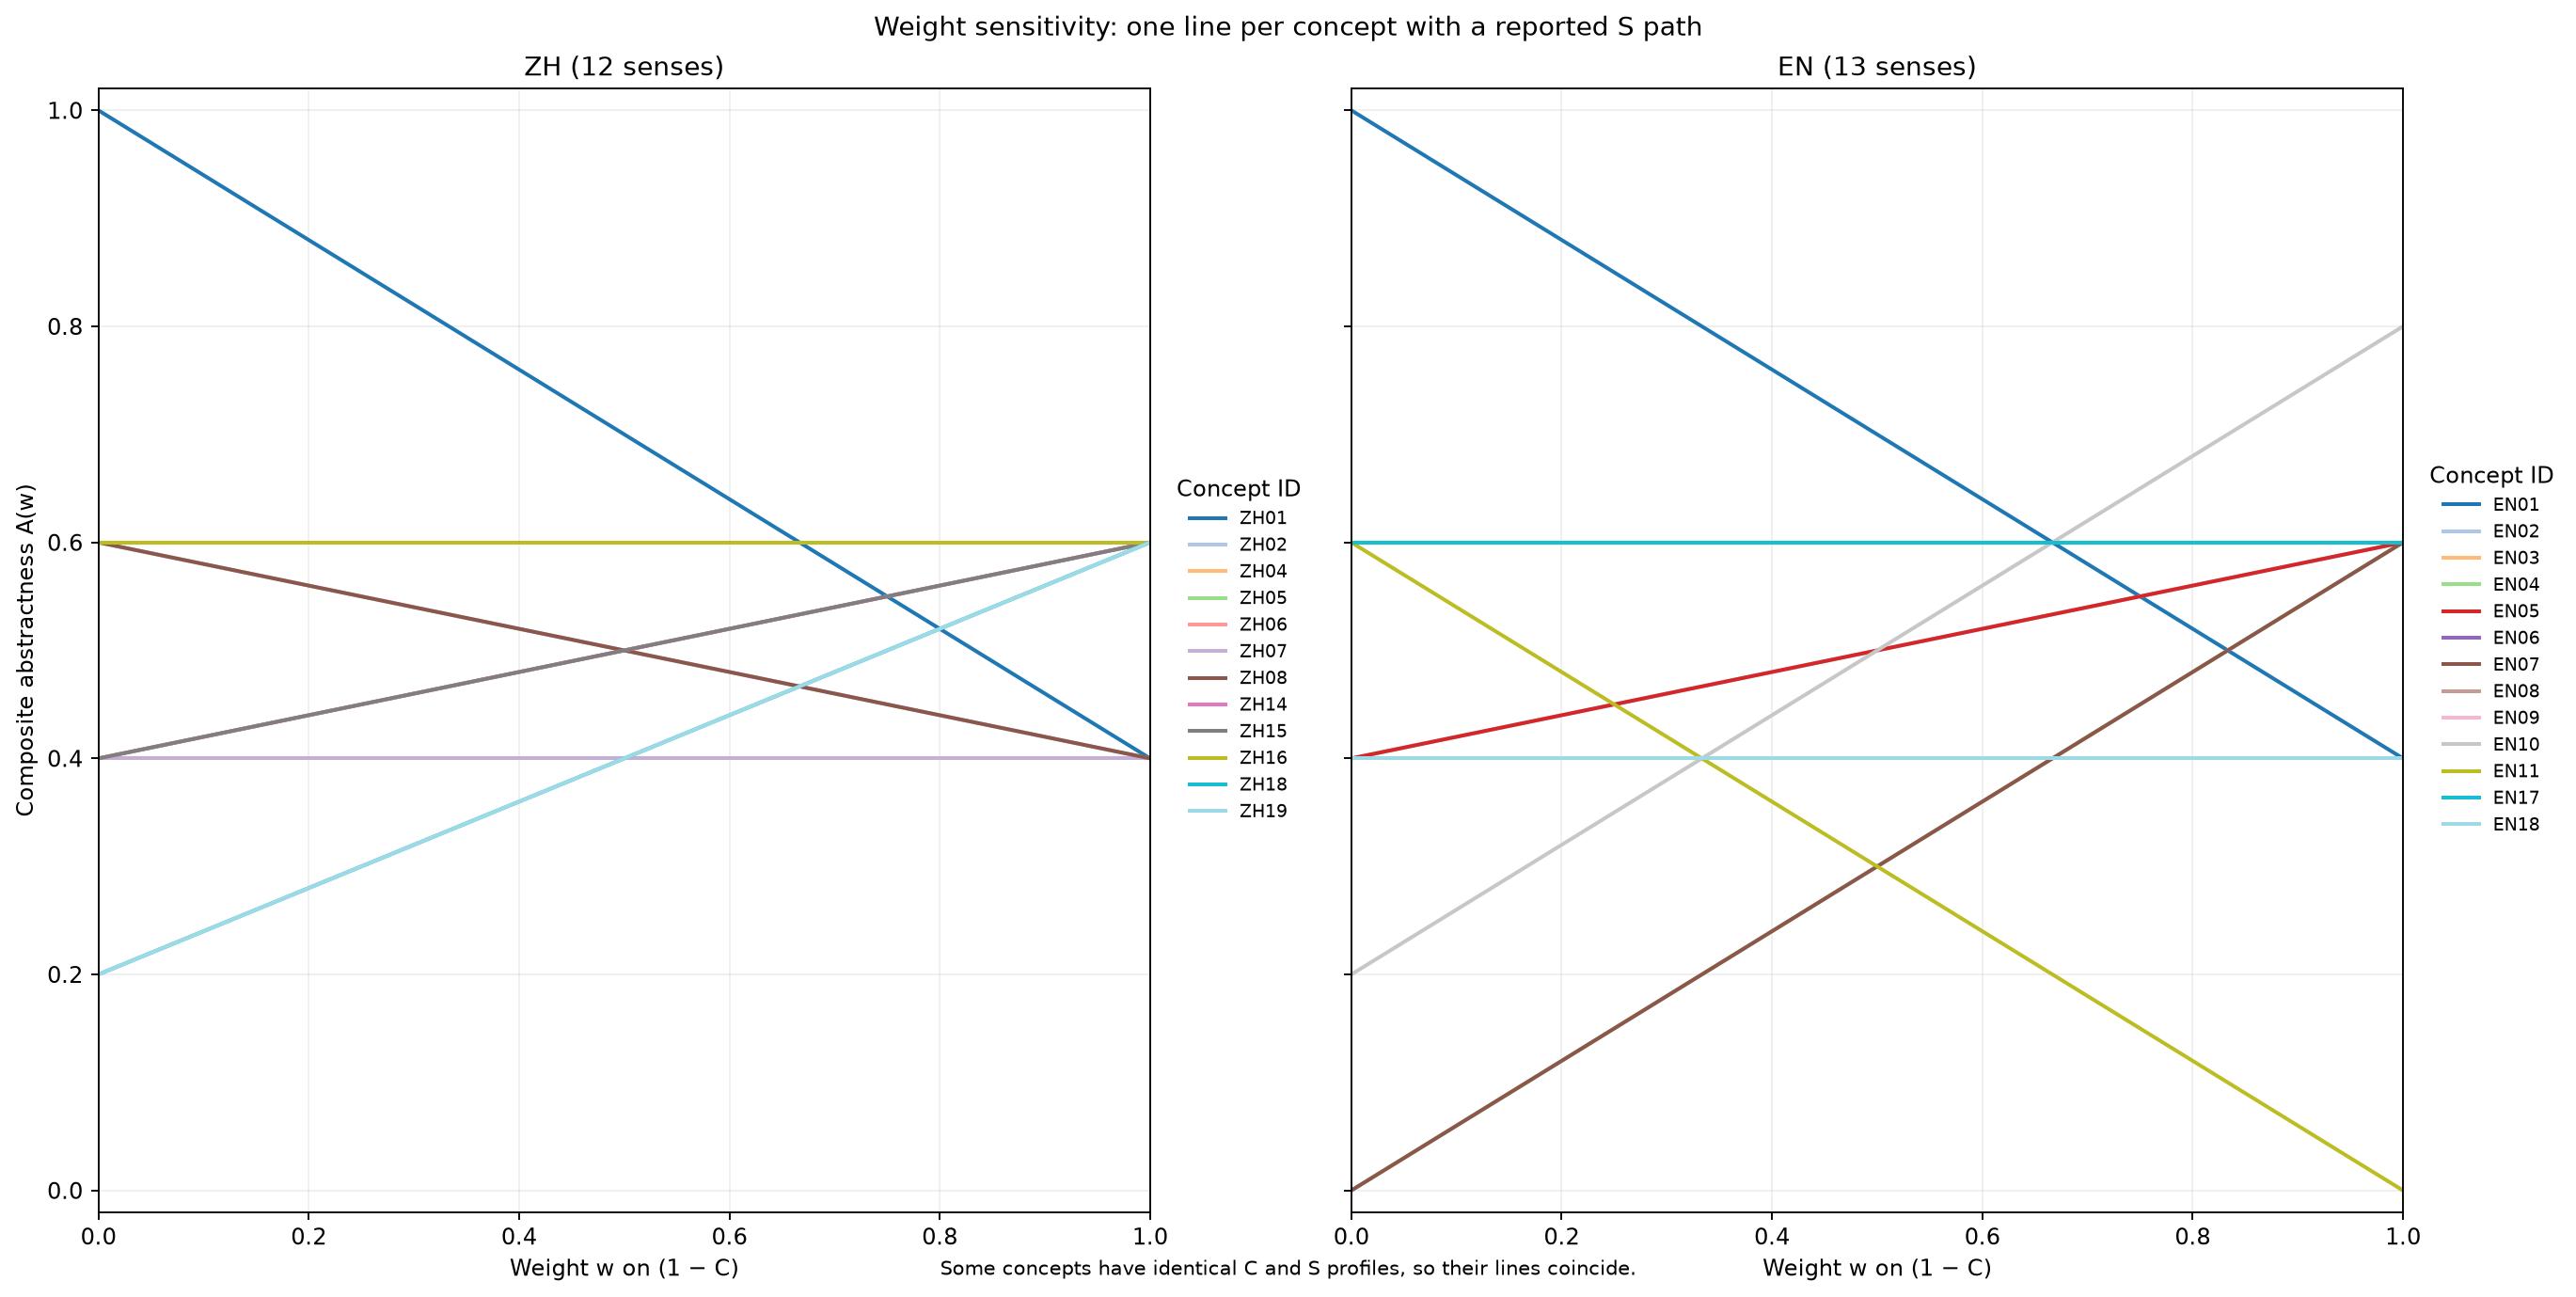

Weight-sensitive senses (>0.1): 15 of 25
Pairwise rank crossings: 83


,concept_id,term,C_norm,S_norm,A_0.2,A_0.8,weight_change
29,EN10,separation,0.2,0.8,0.32,0.68,0.36
20,EN01,location,0.6,0.0,0.88,0.52,0.36
0,ZH01,位置,0.6,0.0,0.88,0.52,0.36
23,EN04,proximity,0.4,1.0,0.12,0.48,0.36
26,EN07,adjacency,0.4,1.0,0.12,0.48,0.36
30,EN11,posture,1.0,0.4,0.48,0.12,0.36
18,ZH19,对称,0.4,0.8,0.28,0.52,0.24
17,ZH18,接触,0.4,0.8,0.28,0.52,0.24


Every fragile sense has a one-sentence explanation: True


In [6]:
sensitivity_file = work / "figures/weight_sensitivity_ha1.png"
weight_sensitivity_plot(scores, sensitivity_file)
display(Image(filename=str(sensitivity_file)))
valid = scores.dropna(subset=["S_norm"]).copy()
valid["weight_change"] = (valid["A_0.8"] - valid["A_0.2"]).abs()
print("Weight-sensitive senses (>0.1):", (valid.weight_change > 0.1).sum(), "of", len(valid))
print("Pairwise rank crossings:", len(crossing_pairs(scores)))
display(valid[["concept_id","term","C_norm","S_norm","A_0.2","A_0.8","weight_change"]]
        .sort_values("weight_change", ascending=False).head(8))
valid["fragile"] = valid["weight_change"] > 0.1
def explain_weight_change(row):
    if abs(row.C_norm - row.S_norm) < 1e-10:
        return "A stays constant because normalized C and S are equal."
    direction = "rises" if row.C_norm < row.S_norm else "falls"
    relation = "lower" if row.C_norm < row.S_norm else "higher"
    return (f"A {direction} by {row.weight_change:.2f} from w=0.2 to 0.8 because "
            f"normalized C is {relation} than normalized S for this target sense.")
valid["one_sentence_reason"] = valid.apply(explain_weight_change, axis=1)
print("Every fragile sense has a one-sentence explanation:", 
      valid.loc[valid.fragile, "one_sentence_reason"].notna().all())


In [7]:
sum_scaled = prepare_scores(inventory, c_aggregation="sum")
active_scaled = prepare_scores(inventory, c_aggregation="active_count")
max_raw = compute_c_raw(inventory, aggregation="max")
print("Mean vs sum normalized C, largest absolute difference:",
      (scores.C_norm - sum_scaled.C_norm).abs().max())
print("Max aggregation unique raw values:", sorted(max_raw.unique()),
      "— min–max scaling is undefined when all are equal.")
print("Mean vs active-channel-count Spearman rho:",
      scores.C_norm.corr(active_scaled.C_norm, method="spearman"))
print("Quadrant changes with active-channel-count C:",
      (scores.quadrant != active_scaled.quadrant).sum())
print("A(0.5) rank association with C-only:",
      scores["A_0.5"].corr(abstractness(scores, 1), method="spearman"))
print("A(0.5) rank association with S-only:",
      scores["A_0.5"].corr(abstractness(scores, 0), method="spearman"))

Mean vs sum normalized C, largest absolute difference: 1.1102230246251565e-16
Max aggregation unique raw values: [np.float64(1.0), np.float64(2.0)] — min–max scaling is undefined when all are equal.


Mean vs active-channel-count Spearman rho: 0.9566590108143047
Quadrant changes with active-channel-count C: 1
A(0.5) rank association with C-only: 0.16567427395302903
A(0.5) rank association with S-only: 0.7421444395307115


### Provenance and cutoff sensitivity

The integrated dataset has already removed the incompatible balance path. This check contrasts the lecture's **dataset-relative min–max C threshold** against the earlier team's fixed raw threshold `C_sum >= 5`, with the same `S_depth >= 6` rule. These cutoffs answer different descriptive questions and should not be merged into a single claim about coverage.

In [8]:
raw_cutoff = scores.copy()
raw_cutoff["raw_quadrant"] = np.where(
    raw_cutoff.S_raw.isna(), "NA_S",
    np.where(raw_cutoff[list(FEATURES)].sum(axis=1) >= 5, "high_C", "low_C")
    + "_" + np.where(raw_cutoff.S_raw >= 6, "high_S", "low_S")
)
display(pd.concat([
    scores.quadrant.value_counts().rename("HA1_minmax_0.5"),
    raw_cutoff.raw_quadrant.value_counts().rename("fixed_raw_cutoff")
], axis=1).fillna(0).astype(int))
print("S=NA is excluded from both four-quadrant comparisons.")

,HA1_minmax_0.5,fixed_raw_cutoff
NA_S,15,15
low_C_high_S,10,12
low_C_low_S,8,12
high_C_low_S,5,1
high_C_high_S,2,0


S=NA is excluded from both four-quadrant comparisons.


## 5. Export

The CSV keeps all 40 senses, including 15 with S=NA, and records raw/normalized C and S plus three A weight settings. Two PNG figures and a sensitivity-detail CSV are also saved. The 280-value source and review audit remains in `data/reviews/feature_score_audit_v3.csv`.

In [9]:
output = work / "ha1_scores_zh20_en20.csv"
export_cols = ["concept_id","language","term","semantic_family","C_rating_source",
               "C_raw","C_norm","S_raw","S_norm","S_source","quadrant",
               "A_0.2","A_0.5","A_0.8"]
scores[export_cols].to_csv(output, index=False, encoding="utf-8", float_format="%.6f")
print("Saved:", output.relative_to(repo))
print("Saved:", scatter_file.relative_to(repo))
print("Saved:", sensitivity_file.relative_to(repo))
sensitivity_output = work / "ha1_weight_sensitivity_details.csv"
valid[["concept_id","language","term","C_norm","S_norm","A_0.2","A_0.8",
       "weight_change","fragile","one_sentence_reason"]].to_csv(
    sensitivity_output, index=False, encoding="utf-8", float_format="%.6f")
print("Saved:", sensitivity_output.relative_to(repo))


Saved: submissions\team\HA1\ha1_scores_zh20_en20.csv
Saved: submissions\team\HA1\figures\cs_scatter_ha1.png
Saved: submissions\team\HA1\figures\weight_sensitivity_ha1.png
Saved: submissions\team\HA1\ha1_weight_sensitivity_details.csv


# HA1 interpretation — team working draft

This simulator uses the 20 Chinese and 20 English spatial-relation senses in the shared HA0 table. Grounding C is the mean of seven 0–2 feature ratings. Specificity S counts root-to-sense edges in the reported taxonomy paths. Both raw measures are separately min–max normalized. Twenty-five senses have reported paths. Fifteen remain S=NA and receive no composite A score; treating missing evidence as zero would falsely classify them as broad concepts.

With dividers at 0.5 on both normalized axes, the plotted senses occupy eight low-C/low-S, ten low-C/high-S, five high-C/low-S, and two high-C/high-S positions. Chinese contributes twelve points and English thirteen. Raw C ranges from 0.143 to 0.857; raw S ranges from three to eight. The high-C/high-S group is small. Fixed raw cutoffs give different counts. Uneven coverage is a result to report, not a reason to raise doubtful feature scores.

The adjustable composite is A(w)=w(1−C)+(1−w)(1−S). Between w=0.2 and w=0.8, fifteen of twenty-five scored senses move by more than 0.1, and 83 concept pairs reverse order. The movement comes from disagreement between the two axes: EN04 has lower normalized C than S and becomes more abstract as C gains weight, whereas EN11 has higher C than S and moves the other way. Rankings therefore need both components and w.

Mean and sum C yield identical normalized positions because they differ only by a constant multiplier. A maximum-channel rule fails here: every sense has at least one channel scored two, so it has no variance. Counting active channels changes one quadrant. Nine flagged feature values retain current scores pending human adjudication. Lexical senses have been manually confirmed by Xia Yuqi, while the feature audit is AI-assisted. The 25 reported S paths still need independent source verification. These are computational proxies, not validated measurements of human abstractness.
